# Introdução ao R com dados de saúde do Brasil (DATASUS)
### Minicurso — 31ª SEMECO 2026 · Economia UEL
**Profa. Natália Trigo**


Neste minicurso vamos aprender o básico de **limpeza e tratamento de microdados** no R usando o `tidyverse` (`dplyr`, `tidyr`, `ggplot2`) e quatro bases públicas do DATASUS, já filtradas para a UF **Paraná**:

| Base | O que é | Unidade de observação | Ano(s) |
|---|---|---|---|
| **SINASC** | Sistema de Informações sobre Nascidos Vivos | 1 linha = 1 nascido vivo | 2015 e 2016 |
| **SIM** | Sistema de Informações sobre Mortalidade (Declarações de Óbito) | 1 linha = 1 óbito | 2016 |
| **SIH/SUS** | Sistema de Informações Hospitalares (AIH reduzida) | 1 linha = 1 AIH (internação paga pelo SUS) | 2016 |
| **CNES-ST** | Cadastro Nacional de Estabelecimentos de Saúde | 1 linha = 1 estabelecimento × mês | 2016 |

Os dados foram baixados com o pacote [`microdatasus`](https://rfsaldanha.github.io/microdatasus/) (Saldanha et al.) e estão no repositório [https://github.com/nattrigo/Semeco2026](https://github.com/nattrigo/Semeco2026). O Dicionário também se encontra no github

**Roteiro**

| Parte | Tema | Funções |
|---|---|---|
| 0 | Aquecimento: R básico no Colab | `c()`, `mean()`, `class()`, `data.frame`, `%>%` |
| 1 | Conhecendo o SINASC | `select`, `filter`, `arrange`, `mutate`, `case_when`, `count`, `group_by` + `summarise`, `pull`, `distinct`, `slice` |
| 2 | Datas e dados faltantes | datas → números, `lubridate`, `drop_na`, `replace_na` |
| 3 | Combinar e dividir | `bind_rows`, `bind_cols`, `separate_wider_*`, `unite` |
| 4 | Internações (SIH) | CID-10, estatísticas por grupo |
| 5 | Juntar bases | `inner_join`, `left_join`, `right_join`, `full_join`, `anti_join` |
| 6 | Reshape | `pivot_wider`, `pivot_longer` |
| 7 | Gráficos | `ggplot2` e escalas de cores |
| 8 | Fechamento | painel municipal juntando as 4 bases |

> 📄 Dica: Deixe aberta a **folha de cola** (PDF)

### Antes de começar (Colab)
1. Abra o notebook pelo botão **Abrir no Colab** acima e clique em **Arquivo → Salvar uma cópia no Drive** (assim você pode editar).
2. Confira se o ambiente é **R**: menu **Ambiente de execução → Alterar o tipo de ambiente de execução → Tipo: R**.
3. Para rodar uma célula: clique nela e aperte **Shift + Enter**.


> Dica: se o Colab "reiniciar" (desconectar), rode de novo as células de **pacotes** e de **download dos dados**.

## Pacotes e opções
O Colab já vem com o `tidyverse` instalado — só precisamos carregar (`library`). Uma linha por pacote.

In [228]:
library(ggplot2)
library(dplyr)
library(tidyr)
library(stringr)
library(lubridate)
library(scales)

options(scipen = 999)                                  # sem notação científica
options(repr.plot.width = 10, repr.plot.height = 6)    # tamanho dos gráficos no Colab

---
# Parte 0 · Aquecimento: R
No R tudo é um **objeto**. Criamos objetos com `<-` ("recebe").

In [229]:
# vetores ----
idade <- c(23, 31, 19, 40, NA)   # c() = "combine"
idade
class(idade)                     # numeric
length(idade)
idade[2]                         # 2º elemento
idade > 30                       # comparação elemento a elemento

mean(idade)                      # NA! um missing "contamina" a conta
mean(idade, na.rm = TRUE)        # na.rm = remove os NA antes

[1] 23 31 19 40 NA

[1] "numeric"

[1] 5

[1] 31

[1] FALSE  TRUE FALSE  TRUE    NA

[1] NA

[1] 28.25

In [230]:
# data.frame: uma tabela em que cada coluna é um vetor ----
df <- data.frame(id    = 1:5,
                 idade = idade,
                 sexo  = c("F", "M", "F", "F", "M"))
df
df$idade          # $ acessa uma coluna
nrow(df)
ncol(df)

id,idade,sexo
<int>,<dbl>,<chr>
1,23,F
2,31,M
3,19,F
4,40,F
5,NA,M


[1] 23 31 19 40 NA

[1] 5

[1] 3

### O pipe `%>%` — leia como **"e então"**
Em vez de aninhar funções (`f(g(x))`), encadeamos passos: `x %>% g() %>% f()`.

In [231]:
# sem pipe
round(mean(df$idade, na.rm = TRUE), 1)

# com pipe: pega df, E ENTÃO filtra, E ENTÃO resume
df %>%
  dplyr::filter(sexo == "F") %>%
  dplyr::summarise(idade_media = mean(idade, na.rm = TRUE))

[1] 28.2

idade_media
<dbl>
27.33333


> Usamos `dplyr::filter()` (com o nome do pacote na frente) para deixar explícito de onde vem cada função — o R base também tem uma `filter()` diferente!

---
## Carregando os dados do GitHub
Os arquivos `.rds` são o formato nativo do R. Baixamos do GitHub para o Colab e lemos com `readRDS()`.

In [232]:

# sinasc
url <- "https://github.com/nattrigo/Semeco2026/raw/main/dados/raw/sinasc/sinasc_2015_pr.rds"
download.file(url, destfile = "sinasc_2015_pr.rds", mode = "wb")
sinasc2015 <- readRDS("sinasc_2015_pr.rds")

url <- "https://github.com/nattrigo/Semeco2026/raw/main/dados/raw/sinasc/sinasc_2016_pr.rds"
download.file(url, destfile = "sinasc_2016_pr.rds", mode = "wb")
sinasc2016 <- readRDS("sinasc_2016_pr.rds")


# cnes
url <- "https://github.com/nattrigo/Semeco2026/raw/main/dados/raw/cnes/cnes_2016_pr.rds"
download.file(url, destfile = "cnes_2016_pr.rds", mode = "wb")
cnes2016 <- readRDS("cnes_2016_pr.rds")

# sim
url <- "https://github.com/nattrigo/Semeco2026/raw/main/dados/raw/sim/sim_2016_pr.rds"
download.file(url, destfile = "sim_2016_pr.rds", mode = "wb")
sim2016 <- readRDS("sim_2016_pr.rds")

# sihsus
url <- "https://github.com/nattrigo/Semeco2026/raw/main/dados/raw/sihsus/sihsus_2016_pr.rds"
download.file(url, destfile = "sihsus_2016_pr.rds", mode = "wb")
sih2016 <- readRDS("sihsus_2016_pr.rds")

In [233]:
# checando tamanho das bases ----
nrow(sinasc2015)  # 160947 nascidos vivos
nrow(sinasc2016)  # 155066
nrow(sim2016)     # 74740 óbitos
nrow(sih2016)     # 811511 AIHs
nrow(cnes2016)    # 268901 estabelecimento x mês

[1] 160947

[1] 155066

[1] 74740

[1] 811511

[1] 268901

---
# Parte 1 · Conhecendo o SINASC com `dplyr`
Pergunta guia: **quem nasce de cesárea no Paraná? O peso ao nascer varia com a escolaridade da mãe?**

In [234]:
## 1.1. primeiro olhar ----
dim(sinasc2016)                 # linhas x colunas


[1] 155066     69

In [235]:
print(colnames(sinasc2016))

 [1] "ORIGEM"       "CODESTAB"     "CODMUNNASC"   "LOCNASC"      "IDADEMAE"    
 [6] "ESTCIVMAE"    "ESCMAE"       "CODOCUPMAE"   "QTDFILVIVO"   "QTDFILMORT"  
[11] "CODMUNRES"    "GESTACAO"     "GRAVIDEZ"     "PARTO"        "CONSULTAS"   
[16] "DTNASC"       "HORANASC"     "SEXO"         "APGAR1"       "APGAR5"      
[21] "RACACOR"      "PESO"         "IDANOMAL"     "DTCADASTRO"   "CODANOMAL"   
[26] "NUMEROLOTE"   "VERSAOSIST"   "DTRECEBIM"    "DIFDATA"      "DTRECORIGA"  
[31] "NATURALMAE"   "CODMUNNATU"   "CODUFNATU"    "ESCMAE2010"   "SERIESCMAE"  
[36] "DTNASCMAE"    "RACACORMAE"   "QTDGESTANT"   "QTDPARTNOR"   "QTDPARTCES"  
[41] "IDADEPAI"     "DTULTMENST"   "SEMAGESTAC"   "TPMETESTIM"   "CONSPRENAT"  
[46] "MESPRENAT"    "TPAPRESENT"   "STTRABPART"   "STCESPARTO"   "TPNASCASSI"  
[51] "TPFUNCRESP"   "TPDOCRESP"    "DTDECLARAC"   "ESCMAEAGR1"   "STDNEPIDEM"  
[56] "STDNNOVA"     "CODPAISRES"   "TPROBSON"     "PARIDADE"     "KOTELCHUCK"  
[61] "CONTADOR"     "munResStatus" "munR

### `select()` — escolher colunas
Microdados têm muitas colunas; trabalhar só com as necessárias deixa tudo mais leve e legível.

In [236]:
## 1.2. select ----
nasc <- sinasc2016 %>%
  dplyr::select(CODESTAB, CODMUNNASC, CODMUNRES, munResNome, LOCNASC,
                DTNASC, SEXO, PESO, GESTACAO, SEMAGESTAC, PARTO, CONSULTAS, APGAR5,
                IDADEMAE, DTNASCMAE, ESCMAE, RACACORMAE, QTDFILVIVO, IDADEPAI)
ncol(nasc)  # 19

# helpers de seleção
sinasc2016 %>% dplyr::select(dplyr::starts_with("QTD")) %>% head(3)
sinasc2016 %>% dplyr::select(dplyr::contains("MAE")) %>% names()

# select também renomeia: novo_nome = nome_antigo
nasc %>% dplyr::select(peso = PESO, idade_mae = IDADEMAE) %>% head(3)

[1] 19

QTDFILVIVO,QTDFILMORT,QTDGESTANT,QTDPARTNOR,QTDPARTCES
<int>,<int>,<int>,<int>,<int>
1,1,2,0,1
0,0,0,0,0
1,0,1,1,0


[1] "IDADEMAE"   "ESTCIVMAE"  "ESCMAE"     "CODOCUPMAE" "NATURALMAE"
 [6] "ESCMAE2010" "SERIESCMAE" "DTNASCMAE"  "RACACORMAE" "ESCMAEAGR1"

peso,idade_mae
<int>,<int>
1540,30
3150,24
3660,25


### `count()` — tabelas de frequência
O jeito mais rápido de conhecer uma variável categórica. Vamos sempre calcular o **percentual** junto.

In [237]:
## 1.3. count ----
nasc %>% dplyr::count(PARTO, name = "n") %>% dplyr::mutate(percent = round(100*n/sum(n), 2))

# equivalente em R base (useNA mostra os missings)
table(nasc$PARTO, useNA = "always")

nasc %>% dplyr::count(ESCMAE, name = "n") %>% dplyr::mutate(percent = round(100*n/sum(n), 2))

PARTO,n,percent
<fct>,<int>,<dbl>
Vaginal,59805,38.57
Cesário,95166,61.37
Ign,4,0.00
NA,91,0.06



Vaginal Cesário     Ign    <NA> 
  59805   95166       4      91 

ESCMAE,n,percent
<fct>,<int>,<dbl>
Nenhuma,377,0.24
01-03,2313,1.49
04-07,23235,14.98
08-11,91843,59.23
12 e+,36636,23.63
Ign,185,0.12
NA,477,0.31


### `filter()` — escolher linhas
Operadores: `==` igual, `!=` diferente, `>`, `<=`, `&` (e), `|` (ou), `%in%` (está na lista), `!` (negação), `is.na()`.

In [238]:
## 1.4. filter ----
nrow(nasc)  # 155066

nasc_hosp <- nasc %>% dplyr::filter(LOCNASC == "Hospital")
nrow(nasc_hosp)  # perdemos os partos em domicílio, outros estab. etc.

# mães adolescentes com cesárea
nasc %>% dplyr::filter(IDADEMAE < 20 & PARTO == "Cesário") %>% nrow()

# mães com baixa escolaridade (lista de categorias)
nasc %>% dplyr::filter(ESCMAE %in% c("Nenhuma", "01-03")) %>% nrow()

# baixo peso ao nascer (< 2500g), tirando os missings
nasc %>% dplyr::filter(!is.na(PESO), PESO < 2500) %>% nrow()

# faixa de valores
nasc %>% dplyr::filter(dplyr::between(IDADEMAE, 15, 19)) %>% nrow()

[1] 155066

[1] 153769

[1] 10650

[1] 2690

[1] 13106

[1] 23063

### `arrange()` — ordenar

In [239]:
## 1.5. arrange ----
nasc %>% dplyr::arrange(PESO) %>% dplyr::select(PESO, SEMAGESTAC, PARTO) %>% head(5)                 # menores pesos
nasc %>% dplyr::arrange(dplyr::desc(IDADEMAE)) %>% dplyr::select(IDADEMAE, PARTO) %>% head(5)         # mães mais velhas

PESO,SEMAGESTAC,PARTO
<int>,<int>,<fct>
157,30,Vaginal
200,33,Cesário
204,33,Cesário
229,35,Cesário
230,36,Vaginal


IDADEMAE,PARTO
<int>,<fct>
63,Vaginal
61,Cesário
60,Cesário
52,Cesário
52,Vaginal


### `mutate()` — criar variáveis
`case_when()` é o "se… então…" do `dplyr`: a primeira condição verdadeira vence; `TRUE ~` pega o resto.

In [240]:
## 1.6. mutate + case_when ----
range(nasc$IDADEMAE, na.rm = TRUE)   # 11 a 63 anos

nasc <- nasc %>% dplyr::mutate(
  cesarea    = dplyr::case_when(
    PARTO == "Cesário" ~ 1,
    PARTO == "Vaginal" ~ 0,
    TRUE ~ NA_real_                  # "Ign" e NA viram missing
  ),
  baixo_peso = dplyr::if_else(PESO < 2500, 1, 0),        # NA continua NA
  prematuro  = dplyr::if_else(SEMAGESTAC < 37, 1, 0),
  faixa_idade_mae = dplyr::case_when(
    IDADEMAE < 20                    ~ "<20",
    dplyr::between(IDADEMAE, 20, 34) ~ "20-34",
    IDADEMAE >= 35                   ~ "35+",
    TRUE ~ NA_character_
  ),
  faixa_idade_mae = factor(faixa_idade_mae, levels = c("<20", "20-34", "35+"))   # fixa a ordem
)

# checando a recodificação: cada categoria de PARTO caiu no lugar certo?
nasc %>% dplyr::count(PARTO, cesarea)
nasc %>% dplyr::count(faixa_idade_mae, name = "n") %>% dplyr::mutate(percent = round(100*n/sum(n), 2))

[1] 11 63

PARTO,cesarea,n
<fct>,<dbl>,<int>
Vaginal,0,59805
Cesário,1,95166
Ign,NA,4
NA,NA,91


faixa_idade_mae,n,percent
<fct>,<int>,<dbl>
<20,24006,15.48
20-34,109411,70.56
35+,21647,13.96
NA,2,0.00


### `group_by()` + `summarise()` — estatísticas por grupo
Médias de variáveis 0/1 são **proporções**: `mean(cesarea)` = taxa de cesárea.

In [241]:
## 1.7. summarise (base toda) ----
nasc %>% dplyr::summarise(
  n            = dplyr::n(),
  peso_medio   = mean(PESO, na.rm = TRUE),
  pct_cesarea  = 100*mean(cesarea, na.rm = TRUE),
  pct_baixo_peso = 100*mean(baixo_peso, na.rm = TRUE)
)

n,peso_medio,pct_cesarea,pct_baixo_peso
<int>,<dbl>,<dbl>,<dbl>
155066,3172.702,61.40891,8.452757


In [242]:
## 1.8. group_by + summarise: por escolaridade da mãe ----
tab_esc <- nasc %>%
  dplyr::group_by(ESCMAE) %>%
  dplyr::summarise(
    n              = dplyr::n(),
    peso_medio     = round(mean(PESO, na.rm = TRUE), 1),
    pct_cesarea    = round(100*mean(cesarea, na.rm = TRUE), 1),
    pct_baixo_peso = round(100*mean(baixo_peso, na.rm = TRUE), 1),
    pct_prematuro  = round(100*mean(prematuro, na.rm = TRUE), 1)
  ) %>%
  dplyr::ungroup()
tab_esc
# a taxa de cesárea cresce MUITO com a escolaridade (proxy de renda / rede privada)

ESCMAE,n,peso_medio,pct_cesarea,pct_baixo_peso,pct_prematuro
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Nenhuma,377,3069.1,44.6,11.7,13.2
01-03,2313,3132.6,44.0,11.5,13.0
04-07,23235,3143.9,45.5,9.5,11.3
08-11,91843,3180.3,58.1,8.2,10.2
12 e+,36636,3175.8,81.2,8.3,10.1
Ign,185,3120.5,46.4,13.2,11.9
NA,477,3180.8,62.3,7.6,12.1


In [243]:
## 1.9. dois grupos ao mesmo tempo ----
nasc %>%
  dplyr::filter(!is.na(faixa_idade_mae)) %>%
  dplyr::group_by(faixa_idade_mae, SEXO) %>%
  dplyr::summarise(n = dplyr::n(),
                   peso_medio = round(mean(PESO, na.rm = TRUE), 1),
                   .groups = "drop")          # .groups = "drop" já desagrupa

faixa_idade_mae,SEXO,n,peso_medio
<fct>,<fct>,<int>,<dbl>
<20,M,12396,3160.4
<20,F,11606,3061.9
<20,I,4,2516.8
20-34,M,55942,3244.1
20-34,F,53458,3129.6
20-34,I,11,2508.2
35+,M,10906,3215.7
35+,F,10739,3106.6
35+,I,2,2500.0


### `pull()`, `distinct()` e `slice()`

In [244]:
## 1.10. pull: tira UMA coluna da tabela e devolve um vetor ----
pesos <- nasc %>% dplyr::pull(PESO)
class(pesos)
summary(pesos)

# útil para guardar um número e usar depois
pct_ces_pr <- nasc %>% dplyr::summarise(m = 100*mean(cesarea, na.rm = TRUE)) %>% dplyr::pull(m)
cat("Taxa de cesárea no PR em 2016:", round(pct_ces_pr, 1), "%\n")

[1] "integer"

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
    157    2900    3205    3173    3505    6390      16 

Taxa de cesárea no PR em 2016: 61.4 %


In [245]:
## 1.11. distinct: valores únicos / remove linhas duplicadas ----
nasc %>% dplyr::distinct(CODMUNRES) %>% nrow()          # 399 municípios do PR
nasc %>% dplyr::distinct(CODMUNRES, munResNome) %>% head()
dplyr::n_distinct(nasc$CODESTAB)                        # nº de estabelecimentos onde houve parto

# checando duplicatas: alguma linha totalmente repetida?
nrow(nasc) - nrow(dplyr::distinct(nasc))                # 17 linhas idênticas: gêmeos com mesmas características ou registro duplicado?
# investigar antes de apagar: dplyr::distinct() removeria essas linhas

[1] 399

CODMUNRES,munResNome
<chr>,<chr>
411820,Paranaguá
411520,Maringá
412810,Umuarama
411990,Ponta Grossa
410020,Adrianópolis
412410,Santo Antônio da Platina


[1] 508

[1] 17

In [246]:
## 1.12. slice: escolher linhas pela posição ----
nasc %>% dplyr::slice(1:3)                              # 3 primeiras linhas
nasc %>% dplyr::slice_max(PESO, n = 3) %>% dplyr::select(PESO, SEMAGESTAC, munResNome)    # 3 maiores pesos
set.seed(2026)
nasc %>% dplyr::slice_sample(n = 5) %>% dplyr::select(DTNASC, PESO, PARTO)                 # amostra aleatória

# 10 municípios com mais nascimentos
nasc %>%
  dplyr::count(munResNome, name = "n_nasc") %>%
  dplyr::slice_max(n_nasc, n = 10)



CODESTAB,CODMUNNASC,CODMUNRES,munResNome,LOCNASC,DTNASC,SEXO,PESO,GESTACAO,SEMAGESTAC,⋯,IDADEMAE,DTNASCMAE,ESCMAE,RACACORMAE,QTDFILVIVO,IDADEPAI,cesarea,baixo_peso,prematuro,faixa_idade_mae
<fct>,<chr>,<chr>,<chr>,<fct>,<date>,<fct>,<int>,<fct>,<int>,⋯,<int>,<date>,<fct>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<fct>
6968139 HOSPITAL DA MULHER PARTEIRA MARIA CORREIA,240800,411820,Paranaguá,Hospital,2016-04-21,M,1540,32 a 36,32,⋯,30,1985-09-21,08-11,Parda,1,NA,1,1,1,20-34
2802090 HOSPITAL REGIONAL DEPUTADO LUIS EDUARDO MAGALHAES,292530,411520,Maringá,Hospital,2016-04-19,F,3150,37 a 41,38,⋯,24,1991-05-20,08-11,Parda,0,NA,0,0,0,20-34
2146355 HOSPITAL DE CLINICAS DE UBERLANDIA,317020,412810,Umuarama,Hospital,2016-03-24,M,3660,37 a 41,39,⋯,25,1990-08-23,08-11,Parda,1,24,0,0,0,20-34


PESO,SEMAGESTAC,munResNome
<int>,<int>,<chr>
6390,39,Arapoti
6315,38,Colombo
5995,40,Turvo


DTNASC,PESO,PARTO
<date>,<int>,<fct>
2016-01-12,3230,Cesário
2016-02-14,3030,Cesário
2016-02-22,2650,Cesário
2016-02-02,2460,Cesário
2016-07-13,2430,Cesário


munResNome,n_nasc
<chr>,<int>
Curitiba,23217
Londrina,7012
Ponta Grossa,5340
São José dos Pinhais,4875
Maringá,4794
Cascavel,4705
Foz do Iguaçu,4198
Colombo,3720
Guarapuava,2847


### ✏️ Exercício — gabarito

In [247]:
# ✏️ Exercício 1 — gabarito ----
nasc %>%
  dplyr::filter(!is.na(RACACORMAE)) %>%
  dplyr::group_by(RACACORMAE) %>%
  dplyr::summarise(
    n           = dplyr::n(),
    peso_medio  = mean(PESO, na.rm = TRUE),
    pct_cesarea = 100*mean(cesarea, na.rm = TRUE)
  ) %>%
  dplyr::arrange(dplyr::desc(pct_cesarea))

RACACORMAE,n,peso_medio,pct_cesarea
<fct>,<int>,<dbl>,<dbl>
Branca,117973,3174.858,63.40690
Amarela,467,3129.709,62.74090
Preta,3508,3144.611,55.28942
Parda,31017,3168.109,54.92049
Indígena,474,3119.247,33.82664


---
# Parte 2 · Datas e dados faltantes
No R, uma data (`Date`) é guardada como **número de dias desde 01/01/1970**. Por isso dá para subtrair datas e obter **dias**.

In [248]:
## 2.1. datas são números ----
class(nasc$DTNASC)                  # Date
as.numeric(as.Date("1970-01-02"))   # 1
as.Date("2016-12-31") - as.Date("2016-01-01")              # diferença de datas
as.numeric(as.Date("2016-12-31") - as.Date("2016-01-01"))  # 365 dias, agora numérico

[1] "Date"

[1] 1

Time difference of 365 days

[1] 365

In [249]:
## 2.2. criar variáveis numéricas a partir das datas ----
nasc <- nasc %>% dplyr::mutate(
  ano_nasc   = lubridate::year(DTNASC),
  mes_nasc   = lubridate::month(DTNASC),
  dia_semana = lubridate::wday(DTNASC, week_start = 1),                # 1 = segunda ... 7 = domingo
  dia_semana = factor(dia_semana, levels = 1:7,
                      labels = c("seg", "ter", "qua", "qui", "sex", "sáb", "dom")),
  idade_mae_dias = as.numeric(DTNASC - DTNASCMAE),                     # diferença em dias
  idade_mae_calc = floor(idade_mae_dias / 365.25)                      # em anos completos
)

nasc %>% dplyr::select(DTNASC, DTNASCMAE, idade_mae_dias, idade_mae_calc, IDADEMAE) %>% head(5)

# checando: a idade calculada bate com a idade declarada (IDADEMAE)?
nasc %>%
  dplyr::mutate(dif = idade_mae_calc - IDADEMAE) %>%
  dplyr::count(dif, name = "n") %>%
  dplyr::mutate(percent = round(100*n/sum(n), 2)) %>%
  dplyr::slice_max(n, n = 5)       # quase tudo 0 (NA = sem data de nasc. da mãe)

DTNASC,DTNASCMAE,idade_mae_dias,idade_mae_calc,IDADEMAE
<date>,<date>,<dbl>,<dbl>,<int>
2016-04-21,1985-09-21,11170,30,30
2016-04-19,1991-05-20,9101,24,24
2016-03-24,1990-08-23,9345,25,25
2016-01-30,1985-10-03,11076,30,30
2016-01-14,1992-03-13,8707,23,23


dif,n,percent
<dbl>,<int>,<dbl>
0,154275,99.49
NA,690,0.44
-1,91,0.06
1,4,0.00
-9,2,0.00


In [250]:
## 2.3. cesárea por dia da semana ----
nasc %>%
  dplyr::group_by(dia_semana) %>%
  dplyr::summarise(n_nasc = dplyr::n(),
                   pct_cesarea = round(100*mean(cesarea, na.rm = TRUE), 1))
# menos nascimentos e menos cesáreas no fim de semana: cesáreas eletivas são agendadas em dias úteis

dia_semana,n_nasc,pct_cesarea
<fct>,<int>,<dbl>
seg,25970,65.6
ter,24396,64.9
qua,23556,63.6
qui,23674,64.3
sex,23934,63.5
sáb,18701,55.0
dom,14835,44.8


### Dados faltantes: `drop_na()` e `replace_na()`
Primeiro **diagnóstico**: quantos NA há em cada coluna?

In [251]:
## 2.4. diagnóstico de missing ----
nasc %>% dplyr::summarise(
  n                = dplyr::n(),
  missing_peso     = sum(is.na(PESO)),
  missing_semagest = sum(is.na(SEMAGESTAC)),
  missing_escmae   = sum(is.na(ESCMAE)),
  missing_idadepai = sum(is.na(IDADEPAI))
)


n,missing_peso,missing_semagest,missing_escmae,missing_idadepai
<int>,<int>,<int>,<int>,<int>
155066,16,1565,477,30502


In [252]:
colSums(is.na(nasc))   # todas as colunas de uma vez

CODESTAB      CODMUNNASC       CODMUNRES      munResNome         LOCNASC 
            533               0               0               0               0 
         DTNASC            SEXO            PESO        GESTACAO      SEMAGESTAC 
              0               0              16            1562            1565 
          PARTO       CONSULTAS          APGAR5        IDADEMAE       DTNASCMAE 
             91               0             347               2             690 
         ESCMAE      RACACORMAE      QTDFILVIVO        IDADEPAI         cesarea 
            477            1627            1410           30502              95 
     baixo_peso       prematuro faixa_idade_mae        ano_nasc        mes_nasc 
             16            1565               2               0               0 
     dia_semana  idade_mae_dias  idade_mae_calc 
              0             690             690

In [253]:
## 2.5. drop_na: remove linhas com NA ----
nrow(nasc)                                        # 155066
nasc %>% tidyr::drop_na() %>% nrow()              # CUIDADO: remove se QUALQUER coluna tiver NA
nasc %>% tidyr::drop_na(PESO, PARTO) %>% nrow()   # só olha essas colunas — perde bem menos

[1] 155066

[1] 120484

[1] 154960

In [254]:
## 2.6. replace_na: substitui NA por um valor ----
# escolaridade NA -> categoria "Ign" (que já existe no fator)
nasc %>% dplyr::count(ESCMAE)
nasc <- nasc %>% tidyr::replace_na(list(ESCMAE = "Ign"))
nasc %>% dplyr::count(ESCMAE)        # não há mais NA

# idade do pai: NA aqui é informação! (pai não declarado). Melhor criar um indicador do que inventar um valor
nasc <- nasc %>% dplyr::mutate(pai_declarado = dplyr::if_else(is.na(IDADEPAI), 0, 1))
nasc %>% dplyr::count(pai_declarado, name = "n") %>% dplyr::mutate(percent = round(100*n/sum(n), 2))
# veremos na Parte 5 o uso mais comum de replace_na: depois de um join, "sem par" = 0

ESCMAE,n
<fct>,<int>
Nenhuma,377
01-03,2313
04-07,23235
08-11,91843
12 e+,36636
Ign,185
NA,477


ESCMAE,n
<fct>,<int>
Nenhuma,377
01-03,2313
04-07,23235
08-11,91843
12 e+,36636
Ign,662


pai_declarado,n,percent
<dbl>,<int>,<dbl>
0,30502,19.67
1,124564,80.33


### ✏️ Exercício — gabarito

In [255]:
# ✏️ Exercício 2 — gabarito ----
nasc %>%
  tidyr::drop_na(SEMAGESTAC) %>%
  dplyr::mutate(trimestre = lubridate::quarter(DTNASC)) %>%
  dplyr::group_by(trimestre) %>%
  dplyr::summarise(n = dplyr::n(),
                   pct_prematuro = 100*mean(prematuro))

trimestre,n,pct_prematuro
<int>,<int>,<dbl>
1,41427,10.959036
2,40500,10.629630
3,37308,10.013938
4,34266,9.939882


---
# Parte 3 · Combinar e dividir
* **`bind_rows()`** empilha bases com as **mesmas colunas** (ex.: anos diferentes) → mais linhas.
* **`bind_cols()`** cola bases lado a lado → mais colunas (perigoso, ver abaixo).
* **`separate_wider_*()`** divide uma coluna em várias; **`unite()`** junta várias em uma.

In [256]:
## 3.1. bind_rows: empilhar SINASC 2015 + 2016 ----
# primeiro: as colunas são as mesmas?
setdiff(names(sinasc2015), names(sinasc2016))   # "contador"
setdiff(names(sinasc2016), names(sinasc2015))   # "CONTADOR"  -> mesmo conteúdo, nome diferente!

teste <- dplyr::bind_rows(sinasc2015, sinasc2016)
ncol(teste)   # 70: virou duas colunas, cada uma com NA para o outro ano
teste %>% dplyr::summarise(na_contador = sum(is.na(contador)), na_CONTADOR = sum(is.na(CONTADOR)))
rm(teste)

[1] "contador"

[1] "CONTADOR"

[1] 70

na_contador,na_CONTADOR
<int>,<int>
155066,160947


In [257]:
# solução: padronizar o nome ANTES de empilhar
sinasc2015 <- sinasc2015 %>% dplyr::rename(CONTADOR = contador)

# .id cria uma coluna dizendo de qual base veio cada linha
sinasc <- dplyr::bind_rows("2015" = sinasc2015, "2016" = sinasc2016, .id = "ano")

ncol(sinasc)                                               # 70 = 69 + ano
nrow(sinasc) == nrow(sinasc2015) + nrow(sinasc2016)        # deve ser TRUE
sinasc %>% dplyr::count(ano)
# checando que "ano" bate com a data de nascimento
sinasc %>% dplyr::count(ano, ano_data = lubridate::year(DTNASC))

[1] 70

[1] TRUE

ano,n
<chr>,<int>
2015,160947
2016,155066


ano,ano_data,n
<chr>,<dbl>,<int>
2015,2015,160947
2016,2016,155066


In [258]:
## 3.2. bind_cols: colar lado a lado ----
parte_a <- nasc %>% dplyr::select(DTNASC, PESO) %>% head(5)
parte_b <- nasc %>% dplyr::select(PARTO, IDADEMAE) %>% head(5)
dplyr::bind_cols(parte_a, parte_b)          # funciona: mesmas linhas, mesma ordem

# PERIGO: se a ordem das linhas muda, o R cola errado e NÃO avisa
parte_b_ord <- parte_b %>% dplyr::arrange(IDADEMAE)
dplyr::bind_cols(parte_a, parte_b_ord)      # bebês misturados com as mães erradas!
# moral: para unir bases por uma chave (id, município, CNES...) use JOIN (Parte 5)

DTNASC,PESO,PARTO,IDADEMAE
<date>,<int>,<fct>,<int>
2016-04-21,1540,Cesário,30
2016-04-19,3150,Vaginal,24
2016-03-24,3660,Vaginal,25
2016-01-30,3415,Vaginal,30
2016-01-14,3500,Cesário,23


DTNASC,PESO,PARTO,IDADEMAE
<date>,<int>,<fct>,<int>
2016-04-21,1540,Cesário,23
2016-04-19,3150,Vaginal,24
2016-03-24,3660,Vaginal,25
2016-01-30,3415,Cesário,30
2016-01-14,3500,Vaginal,30


### `separate_wider_delim()` — dividir uma coluna
A variável `CODESTAB` do SINASC traz **código CNES + nome** do estabelecimento na mesma célula. Precisamos do código separado para juntar com o CNES depois.

In [259]:
## 3.3. separate_wider_delim ----
class(nasc$CODESTAB)                         # factor
nasc %>% dplyr::distinct(CODESTAB) %>% head(3)

nasc <- nasc %>%
  dplyr::mutate(CODESTAB = as.character(CODESTAB)) %>%
  tidyr::separate_wider_delim(CODESTAB, delim = " ",
                              names = c("cod_cnes", "nome_estab"),
                              too_many = "merge",          # o nome tem espaços: junta todo o resto
                              too_few  = "align_start",    # se faltar pedaço, completa com NA
                              cols_remove = FALSE)         # mantém a coluna original
nasc %>% dplyr::count(cod_cnes, nome_estab, sort = TRUE) %>% head(5)
sum(is.na(nasc$cod_cnes))    # partos fora de estabelecimento (domicílio etc.)

[1] "factor"

CODESTAB
<fct>
6968139 HOSPITAL DA MULHER PARTEIRA MARIA CORREIA
2802090 HOSPITAL REGIONAL DEPUTADO LUIS EDUARDO MAGALHAES
2146355 HOSPITAL DE CLINICAS DE UBERLANDIA


cod_cnes,nome_estab,n
<chr>,<chr>,<int>
3000907,HOSPITAL E MATERNIDADE SANTA BRIGIDA,4979
2715864,HOSPITAL NOSSA SRA DAS GRACAS MATERNIDADE MATER DEI,4209
2591049,HOSPITAL MINISTRO COSTA CAVALCANTI,4016
2594714,SANTA CASA DE MARINGA HOSPITAL E MAT M AUXILIADORA,3815
3000869,HOSPITAL SANTA CRUZ,3614


[1] 533

In [260]:
## 3.4. separate_wider_position: dividir por posição ----
# CID-10 da causa básica do óbito (SIM): letra = capítulo, 2 dígitos = categoria
sim2016 %>%
  dplyr::select(CAUSABAS) %>%
  tidyr::separate_wider_position(CAUSABAS, widths = c(cid_letra = 1, cid_num = 2),
                                 too_many = "drop", cols_remove = FALSE) %>%
  head(5)

cid_letra,cid_num,CAUSABAS
<chr>,<chr>,<chr>
G,31,G311
I,21,I219
I,62,I620
C,34,C349
I,10,I10


In [261]:
## 3.5. unite: juntar colunas ----
# chave "ano-mes" para contar nascimentos por mês nos 2 anos
sinasc %>%
  dplyr::mutate(mes = stringr::str_pad(lubridate::month(DTNASC), width = 2, pad = "0")) %>%   # "1" -> "01" para ordenar certo
  tidyr::unite("ano_mes", ano, mes, sep = "-", remove = FALSE) %>%
  dplyr::count(ano_mes) %>%
  head(6)

ano_mes,n
<chr>,<int>
2015-01,14165
2015-02,12968
2015-03,14932
2015-04,14112
2015-05,14322
2015-06,13375


### ✏️ Exercício — gabarito

In [262]:
# ✏️ Exercício 3 — gabarito ----
sim2016 %>%
  dplyr::select(ATESTADO) %>%
  tidyr::separate_wider_delim(ATESTADO, delim = "/",
                              names = c("causa_1", "causa_2", "causa_3"),
                              too_many = "merge", too_few = "align_start") %>%
  dplyr::count(causa_1, sort = TRUE) %>%
  head(10)

causa_1,n
<chr>,<int>
A419,10473
J960,4933
R092,3892
R688,3774
J969,3271
I219,3094
R570,2844
I469,2319
S069,1671


---
# Parte 4 · Internações hospitalares (SIH/SUS)
Pergunta guia: **quais doenças mais internam no SUS do PR? Quanto tempo ficam internados, quanto custam e qual a letalidade?**

In [263]:
## 4.1. selecionar e liberar memória ----
sih <- sih2016 %>%
  dplyr::select(N_AIH, IDENT, MES_CMPT, MUNIC_RES, NASC, SEXO, RACA_COR,
                DT_INTER, DT_SAIDA, DIAS_PERM, DIAG_PRINC, PROC_REA, CAR_INT,
                MARCA_UTI, UTI_MES_TO, VAL_TOT, MORTE, NAT_JUR,
                CNES, CGC_HOSP, CNPJ_MANT)
dim(sih)
rm(sih2016); gc()   # Clear memory: a base original tem 124 colunas

[1] 811511     21

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2590218,138.4,7393688,394.9,7393688,394.9
Vcells,99523358,759.4,281267846,2146.0,281256988,2145.9


In [264]:
## 4.2. qual é a unidade de observação? ----
nrow(sih)                        # 811511 linhas
dplyr::n_distinct(sih$N_AIH)     # menos AIHs únicas -> há AIHs repetidas

sih %>% dplyr::count(N_AIH) %>% dplyr::filter(n > 1) %>% head(3)
sih %>% dplyr::count(IDENT, name = "n") %>% dplyr::mutate(percent = round(100*n/sum(n), 2))

# exemplo: AIH de longa permanência é reapresentada TODO MÊS
sih %>%
  dplyr::filter(N_AIH == "4108103191600") %>%
  dplyr::select(N_AIH, IDENT, MES_CMPT, DT_INTER, DT_SAIDA, DIAS_PERM)

[1] 811511

[1] 795260

N_AIH,n
<chr>,<int>
4108103191600,12
4108104999713,6
4108104999735,6


IDENT,n,percent
<fct>,<int>,<dbl>
Normal,793912,97.83
Longa permanência,17599,2.17


N_AIH,IDENT,MES_CMPT,DT_INTER,DT_SAIDA,DIAS_PERM
<chr>,<fct>,<int>,<date>,<date>,<int>
4108103191600,Longa permanência,1,2008-07-15,2016-01-31,31
4108103191600,Longa permanência,2,2008-07-15,2016-02-29,29
4108103191600,Longa permanência,3,2008-07-15,2016-03-31,31
4108103191600,Longa permanência,4,2008-07-15,2016-04-30,30
4108103191600,Longa permanência,5,2008-07-15,2016-05-31,31
4108103191600,Longa permanência,6,2008-07-15,2016-06-30,30
4108103191600,Longa permanência,7,2008-07-15,2016-07-31,31
4108103191600,Longa permanência,8,2008-07-15,2016-08-31,31
4108103191600,Longa permanência,9,2008-07-15,2016-09-30,30


In [265]:
# ficamos com as AIHs "Normal" -> 1 linha = 1 internação
sih <- sih %>% dplyr::filter(IDENT == "Normal")
nrow(sih)                                        # 793912
nrow(sih) == dplyr::n_distinct(sih$N_AIH)        # checando que é 1 row per AIH: TRUE

# residentes de outros estados internados no PR: código do município começa com 41 no PR
sih %>% dplyr::count(uf_res = stringr::str_sub(MUNIC_RES, 1, 2), sort = TRUE) %>% head(4)
sih <- sih %>% dplyr::filter(stringr::str_sub(MUNIC_RES, 1, 2) == "41")
nrow(sih)

[1] 793912

[1] TRUE

uf_res,n
<chr>,<int>
41,785790
42,4972
35,983
50,866


[1] 785790

In [266]:
## 4.3. datas -> números: tempo de internação e idade ----
sih <- sih %>% dplyr::mutate(
  dias_calc  = as.numeric(DT_SAIDA - DT_INTER),
  idade_calc = floor(as.numeric(DT_INTER - NASC) / 365.25),
  faixa_etaria = dplyr::case_when(
    idade_calc < 5                    ~ "0-4",
    dplyr::between(idade_calc, 5, 14)  ~ "5-14",
    dplyr::between(idade_calc, 15, 59) ~ "15-59",
    idade_calc >= 60                  ~ "60+"
  ),
  faixa_etaria = factor(faixa_etaria, levels = c("0-4", "5-14", "15-59", "60+"))
)
# checando: os dias calculados batem com DIAS_PERM?
sih %>% dplyr::summarise(igual = mean(dias_calc == DIAS_PERM))
summary(sih$idade_calc)

igual
<dbl>
1


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00   23.00   42.00   42.26   62.00  116.00 

In [267]:
## 4.4. capítulos da CID-10 a partir do diagnóstico principal ----
sih <- sih %>%
  tidyr::separate_wider_position(DIAG_PRINC, widths = c(cid_letra = 1, cid_num = 2),
                                 too_many = "drop", cols_remove = FALSE) %>%
  dplyr::mutate(
    cid3  = paste0(cid_letra, cid_num),
    cid_n = suppressWarnings(as.numeric(cid_num)),
    capitulo = dplyr::case_when(
      cid_letra %in% c("A", "B")                         ~ "Infecciosas (A-B)",
      cid_letra == "C" | (cid_letra == "D" & cid_n <= 48) ~ "Neoplasias (C-D48)",
      cid_letra == "F"                                   ~ "Mentais (F)",
      cid_letra == "I"                                   ~ "Circulatório (I)",
      cid_letra == "J"                                   ~ "Respiratório (J)",
      cid_letra == "K"                                   ~ "Digestivo (K)",
      cid_letra == "N"                                   ~ "Geniturinário (N)",
      cid_letra == "O"                                   ~ "Gravidez e parto (O)",
      cid_letra == "P"                                   ~ "Perinatal (P)",
      cid_letra %in% c("S", "T")                         ~ "Lesões (S-T)",
      TRUE                                               ~ "Outros"
    )
  )
sih %>% dplyr::count(capitulo, name = "n") %>% dplyr::mutate(percent = round(100*n/sum(n), 2)) %>% dplyr::arrange(dplyr::desc(n))

capitulo,n,percent
<chr>,<int>,<dbl>
Gravidez e parto (O),120327,15.31
Outros,111083,14.14
Circulatório (I),99931,12.72
Respiratório (J),99773,12.70
Lesões (S-T),83702,10.65
Digestivo (K),77713,9.89
Neoplasias (C-D48),63897,8.13
Geniturinário (N),49093,6.25
Infecciosas (A-B),43340,5.52


In [268]:
## 4.5. top 10 diagnósticos (CID 3 dígitos) ----
sih %>%
  dplyr::count(cid3, name = "n_intern") %>%
  dplyr::slice_max(n_intern, n = 10)
# O80 = parto normal; J18 = pneumonia; I50 = insuficiência cardíaca; O82 = cesariana...

# urgência x eletiva
sih %>%
  dplyr::group_by(CAR_INT) %>%
  dplyr::summarise(n = dplyr::n(), dias_medio = mean(DIAS_PERM), letalidade = 100*mean(MORTE)) %>%
  dplyr::arrange(dplyr::desc(n)) %>%
  head(4)

cid3,n_intern
<chr>,<int>
O80,51301
J18,35594
I50,22573
O82,21104
I20,19879
K80,10958
S52,10692
N39,10598
J44,10591


CAR_INT,n,dias_medio,letalidade
<fct>,<int>,<dbl>,<dbl>
02 Urgência,623278,4.514822,4.8379696
01 Eletivo,154218,2.612432,0.9609773
06 Out tp lesões e envenen por agent quím físicos,5894,3.514591,1.9850696
05 Outros tipo de acidente de trânsito,2399,4.825761,2.9595665


### ✏️ Exercício — gabarito

In [269]:
# ✏️ Exercício 4 — gabarito ----
sih %>%
  dplyr::filter(capitulo == "Respiratório (J)") %>%
  dplyr::group_by(faixa_etaria) %>%
  dplyr::summarise(n_intern   = dplyr::n(),
                   dias_medio = mean(DIAS_PERM),
                   letalidade = 100*mean(MORTE))

faixa_etaria,n_intern,dias_medio,letalidade
<fct>,<int>,<dbl>,<dbl>
0-4,23438,3.920514,0.4821230
5-14,9546,2.304106,0.2618898
15-59,28285,4.115114,4.7622415
60+,38504,5.088822,13.3856223


---
# Parte 5 · Juntando bases (joins)
Um *join* une duas tabelas pelas **colunas-chave** em comum. A diferença entre os tipos é **o que acontece com quem não encontra par**:

| Função | Mantém | Linhas sem par |
|---|---|---|
| `inner_join(x, y)` | só quem está em **x e y** | descartadas |
| `left_join(x, y)` | **todas de x** | colunas de y viram `NA` |
| `right_join(x, y)` | **todas de y** | colunas de x viram `NA` |
| `full_join(x, y)` | **todas** de x e y | `NA` dos dois lados |
| `anti_join(x, y)` | linhas de x **sem par** em y | (diagnóstico!) |
| `semi_join(x, y)` | linhas de x **com par** em y | sem trazer colunas de y |

In [270]:
## 5.1. exemplo de brinquedo ----
pacientes <- dplyr::tibble(nome     = c("Ana", "Bia", "Caio", "Davi"),
                           cod_hosp = c("H1",  "H2",  "H1",   "H9"))
hospitais <- dplyr::tibble(cod_hosp = c("H1", "H2", "H3"),
                           rede     = c("Pública", "Filantrópica", "Privada"))
pacientes
hospitais

nome,cod_hosp
<chr>,<chr>
Ana,H1
Bia,H2
Caio,H1
Davi,H9


cod_hosp,rede
<chr>,<chr>
H1,Pública
H2,Filantrópica
H3,Privada


In [271]:
dplyr::inner_join(pacientes, hospitais, by = "cod_hosp")   # 3 linhas: Davi (H9) some
dplyr::left_join(pacientes, hospitais, by = "cod_hosp")    # 4 linhas: Davi fica, rede = NA
dplyr::right_join(pacientes, hospitais, by = "cod_hosp")   # H3 aparece sem paciente
dplyr::full_join(pacientes, hospitais, by = "cod_hosp")    # todo mundo
dplyr::anti_join(pacientes, hospitais, by = "cod_hosp")    # quem ficou sem par: Davi

nome,cod_hosp,rede
<chr>,<chr>,<chr>
Ana,H1,Pública
Bia,H2,Filantrópica
Caio,H1,Pública


nome,cod_hosp,rede
<chr>,<chr>,<chr>
Ana,H1,Pública
Bia,H2,Filantrópica
Caio,H1,Pública
Davi,H9,NA


nome,cod_hosp,rede
<chr>,<chr>,<chr>
Ana,H1,Pública
Bia,H2,Filantrópica
Caio,H1,Pública
NA,H3,Privada


nome,cod_hosp,rede
<chr>,<chr>,<chr>
Ana,H1,Pública
Bia,H2,Filantrópica
Caio,H1,Pública
Davi,H9,NA
NA,H3,Privada


nome,cod_hosp
<chr>,<chr>
Davi,H9


### 5.2. SINASC × CNES: onde as crianças nascem?
O CNES tem **1 linha por estabelecimento por mês**. Para o join, a chave do lado do CNES precisa ser **única** → ficamos com a competência mais recente de cada estabelecimento.

In [272]:
## 5.2.1. CNES: 1 linha por estabelecimento ----
nrow(cnes2016)                       # 268901
dplyr::n_distinct(cnes2016$CNES)     # 23319 estabelecimentos
cnes2016 %>% dplyr::count(COMPETEN)  # 12 meses

cnes <- cnes2016 %>%
  dplyr::group_by(CNES) %>%
  dplyr::slice_max(COMPETEN, n = 1, with_ties = FALSE) %>%    # competência mais recente
  dplyr::ungroup() %>%
  dplyr::select(CNES, CPF_CNPJ, CODUFMUN, COD_CEP, TP_UNID, NAT_JUR, VINC_SUS,
                TPGESTAO, LEITHOSP, URGEMERG, CENTROBS, CENTRNEO)
nrow(cnes)
cnes %>% dplyr::count(CNES) %>% dplyr::filter(n > 1) %>% nrow()    # deve ser 0

[1] 268901

[1] 23319

COMPETEN,n
<chr>,<int>
201601,21947
201602,22023
201603,22078
201604,22197
201605,22263
201606,22370
201607,22462
201608,22532
201609,22640


[1] 23319

[1] 0

In [273]:
## 5.2.3. o join ----
# chaves precisam ter o MESMO tipo nos dois lados
class(nasc$cod_cnes); class(cnes$CNES)     # character / character

nasc_left  <- nasc %>% dplyr::left_join(cnes,  by = c("cod_cnes" = "CNES"))
nasc_inner <- nasc %>% dplyr::inner_join(cnes, by = c("cod_cnes" = "CNES"))
nrow(nasc); nrow(nasc_left); nrow(nasc_inner)
# left mantém os 155066; inner perde quem não achou estabelecimento no CNES-PR

# quem ficou sem par? anti_join para investigar
nasc %>%
  dplyr::anti_join(cnes, by = c("cod_cnes" = "CNES")) %>%
  dplyr::count(LOCNASC, uf_nasc = stringr::str_sub(CODMUNNASC, 1, 2), sort = TRUE) %>%
  head(5)
# 42 = SC, 35 = SP: residentes do PR que nasceram em outro estado (CNES aqui é só do PR) + partos em domicílio

[1] "character"

[1] "character"

[1] 155066

[1] 155066

[1] 153242

LOCNASC,uf_nasc,n
<fct>,<chr>,<int>
Hospital,42,683
Hospital,35,481
Domicílio,41,356
Outros,41,165
Hospital,41,82


---
# Parte 6 · Reshape: formato longo ⇄ largo
* **Longo** (*long*): uma linha por unidade × período. Bom para `ggplot2` e para regressões.
* **Largo** (*wide*): uma coluna por período. Bom para tabelas e para comparar colunas (variação entre anos).

In [274]:
## 6.1. pivot_wider: internações por capítulo (linhas) x mês (colunas) ----
tab_long <- sih %>% dplyr::count(capitulo, MES_CMPT, name = "n_intern")
head(tab_long)
nrow(tab_long)       # 11 capítulos x 12 meses = 132 linhas

tab_wide <- tab_long %>%
  tidyr::pivot_wider(names_from = MES_CMPT, values_from = n_intern, names_prefix = "mes_")
tab_wide

capitulo,MES_CMPT,n_intern
<chr>,<int>,<int>
Circulatório (I),1,7735
Circulatório (I),2,7736
Circulatório (I),3,8327
Circulatório (I),4,8038
Circulatório (I),5,8349
Circulatório (I),6,8346


[1] 132

capitulo,mes_1,mes_2,mes_3,mes_4,mes_5,mes_6,mes_7,mes_8,mes_9,mes_10,mes_11,mes_12
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
Circulatório (I),7735,7736,8327,8038,8349,8346,8678,8699,8506,8859,8374,8284
Digestivo (K),6016,6053,6562,6477,6562,6541,6570,6924,6808,6581,6493,6126
Geniturinário (N),3878,3981,4244,4149,4227,3849,3920,4083,4122,4283,4349,4008
Gravidez e parto (O),10615,10094,10678,10423,10915,10103,9732,9727,9713,9234,9247,9846
Infecciosas (A-B),3658,4037,4061,4095,3952,3271,3164,3303,3538,3375,3552,3334
Lesões (S-T),6730,6775,6749,7172,7101,7054,6944,6928,6909,7035,7333,6972
Mentais (F),1645,1684,1733,1674,1638,1798,1654,1743,1816,1902,1826,1752
Neoplasias (C-D48),5008,5033,5449,5311,5430,5230,5419,5513,5464,5423,5228,5389
Outros,8491,8412,9406,9258,9353,9185,9691,9705,9504,9664,9520,8894


In [275]:
## 6.2. pivot_longer: de volta ao formato longo ----
tab_long2 <- tab_wide %>%
  tidyr::pivot_longer(cols = dplyr::starts_with("mes_"),
                      names_to = "mes", names_prefix = "mes_",
                      values_to = "n_intern") %>%
  dplyr::mutate(mes = as.numeric(mes))
head(tab_long2)
nrow(tab_long2) == nrow(tab_long)   # TRUE

capitulo,mes,n_intern
<chr>,<dbl>,<int>
Circulatório (I),1,7735
Circulatório (I),2,7736
Circulatório (I),3,8327
Circulatório (I),4,8038
Circulatório (I),5,8349
Circulatório (I),6,8346


[1] TRUE

In [276]:
## 6.3. wide é útil para variação entre anos: nascimentos por município 2015 x 2016 ----
nasc_mun_ano <- sinasc %>%
  dplyr::count(CODMUNRES, munResNome, ano, name = "n_nasc") %>%
  tidyr::pivot_wider(names_from = ano, values_from = n_nasc, names_prefix = "nasc_") %>%
  dplyr::mutate(var_pct = round(100*(nasc_2016 - nasc_2015)/nasc_2015, 1))

nasc_mun_ano %>% dplyr::arrange(dplyr::desc(nasc_2016)) %>% head(8)
# os nascimentos caíram de 2015 para 2016 na maioria dos municípios (recessão + surto de Zika são hipóteses discutidas na literatura)
nasc_mun_ano %>% dplyr::summarise(pct_mun_queda = round(100*mean(var_pct < 0, na.rm = TRUE), 1))

CODMUNRES,munResNome,nasc_2015,nasc_2016,var_pct
<chr>,<chr>,<int>,<int>,<dbl>
410690,Curitiba,24506,23217,-5.3
411370,Londrina,7365,7012,-4.8
411990,Ponta Grossa,5375,5340,-0.7
412550,São José dos Pinhais,5078,4875,-4.0
411520,Maringá,5087,4794,-5.8
410480,Cascavel,4768,4705,-1.3
410830,Foz do Iguaçu,4327,4198,-3.0
410580,Colombo,3854,3720,-3.5


pct_mun_queda
<dbl>
61.4


---
# Parte 7 · Visualização com `ggplot2`
A "gramática dos gráficos": **dados** + **estética** (`aes`: o que vai no x, y, cor...) + **geometria** (`geom_*`: barras, linhas, pontos) + **escalas** (`scale_*`: cores, eixos) + **tema**.

```r
ggplot(dados, aes(x = ..., y = ..., fill = ...)) +
  geom_col() +
  scale_fill_manual(values = ...) +
  labs(...) +
  theme_minimal()
```

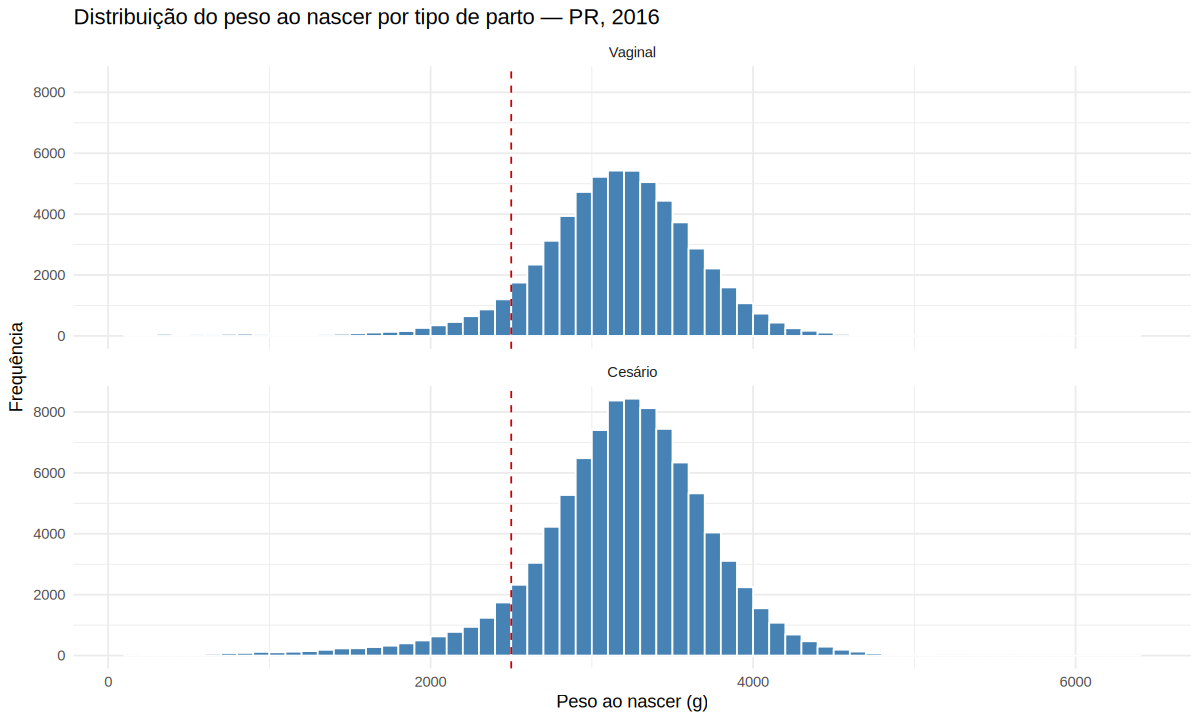

In [277]:
## 7.1. histograma: distribuição do peso ao nascer ----
nasc %>%
  dplyr::filter(!is.na(PESO), PARTO %in% c("Vaginal", "Cesário")) %>%
  ggplot(aes(x = PESO)) +
  geom_histogram(binwidth = 100, boundary = 0, color = "white", fill = "steelblue") +
  geom_vline(xintercept = 2500, color = "red3", linetype = "dashed") +   # linha do baixo peso
  facet_wrap(~ PARTO, ncol = 1) +                                         # um painel por tipo de parto
  labs(x = "Peso ao nascer (g)", y = "Frequência",
       title = "Distribuição do peso ao nascer por tipo de parto — PR, 2016") +
  theme_minimal()

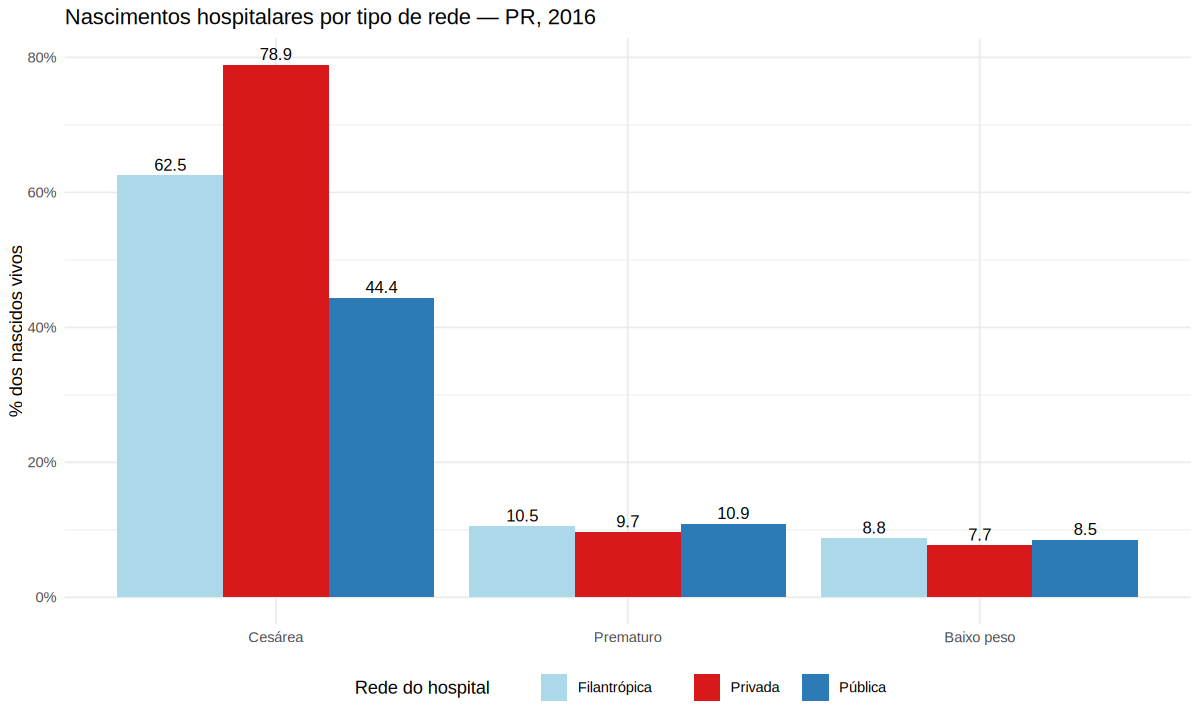

In [278]:
## 7.2. barras com cores manuais: indicadores por rede ----
cores_rede <- c("Pública" = "#2c7bb6", "Filantrópica" = "#abd9e9", "Privada" = "#d7191c")

tab_rede_long %>%
  dplyr::mutate(indicador = factor(indicador, levels = c("cesarea", "prematuro", "baixo_peso"),
                                   labels = c("Cesárea", "Prematuro", "Baixo peso"))) %>%
  ggplot(aes(x = indicador, y = pct, fill = rede)) +
  geom_col(position = "dodge") +
  geom_text(aes(label = round(pct, 1)), position = position_dodge(width = 0.9), vjust = -0.4, size = 3.5) +
  scale_fill_manual(values = cores_rede) +
  scale_y_continuous(labels = scales::percent_format(scale = 1)) +
  labs(x = NULL, y = "% dos nascidos vivos", fill = "Rede do hospital",
       title = "Nascimentos hospitalares por tipo de rede — PR, 2016") +
  theme_minimal() +
  theme(legend.position = "bottom")

### ✏️ Exercício — gabarito

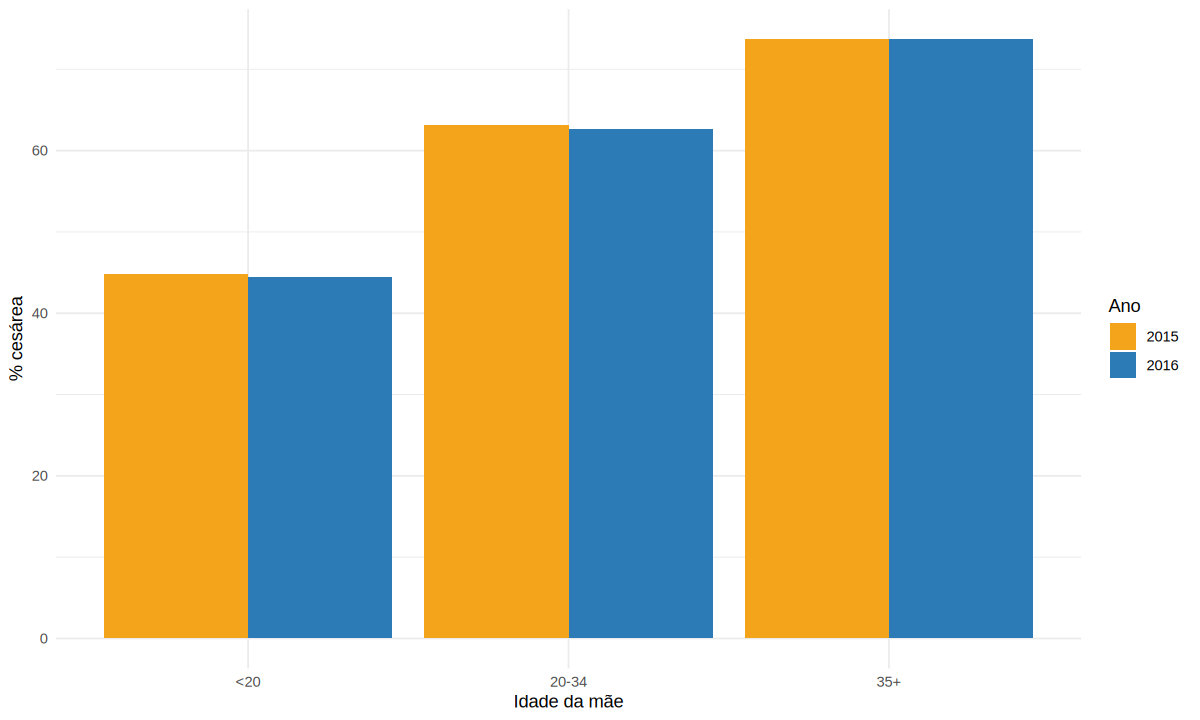

In [279]:
# ✏️ Exercício 7 — gabarito ----
sinasc %>%
  dplyr::filter(PARTO %in% c("Vaginal", "Cesário"), !is.na(IDADEMAE)) %>%
  dplyr::mutate(faixa_idade_mae = dplyr::case_when(IDADEMAE < 20 ~ "<20",
                                                   IDADEMAE < 35 ~ "20-34",
                                                   TRUE ~ "35+")) %>%
  dplyr::group_by(faixa_idade_mae, ano) %>%
  dplyr::summarise(pct_cesarea = 100*mean(PARTO == "Cesário"), .groups = "drop") %>%
  ggplot(aes(x = faixa_idade_mae, y = pct_cesarea, fill = ano)) +
  geom_col(position = "dodge") +
  scale_fill_manual(values = c("2015" = "#f4a41b", "2016" = "#2c7bb6")) +
  labs(x = "Idade da mãe", y = "% cesárea", fill = "Ano") +
  theme_minimal()

---
## Para continuar estudando
* **R for Data Science (2ª ed., em português)**: <https://cienciadedatos.github.io/pt-r4ds/>
* **Pacote microdatasus** (baixar outras UFs/anos): <https://rfsaldanha.github.io/microdatasus/>
* **Dicionários das bases (SINASC, SIM, SIH, CNES)**: <https://rfsaldanha.github.io/sis/>
* **ggplot2 — galeria de gráficos**: <https://r-graph-gallery.com/> · **From Data to Viz**: <https://www.data-to-viz.com/>
* Para baixar os dados você mesmo: veja `code/download_rawdata.R` no repositório do curso.

**Obrigada!**
